# 04 — The equator, the two counter-rotating waves, and the primes on the springs

**Assistant note.** Written by an AI assistant (Claude) with the author, from `rhp/sphere.py`, `rhp/wrap.py` and the figures in `rhp/atlas_riemann_fermat/`
(each picture sits next to the code that draws it). Labels: ESTABLISHED, OURS, THEORETICAL, CONJECTURE, OPEN; `:CALCULATED` = this code reproduces it.
**This notebook sets up a space and machinery; it proves nothing.** RH is the statement that every zero lies on the circle drawn here.
Standing protocol (Chase Every Anomaly): the unexpected results are in §7.

**Vantage point.** Orientation: the Riemann sphere of w = (s−1)/s (north pole = ζ's pole at s = 1); longitude is the Hardy phase θ(t) mod 2π (the spring end-on).
Aperture: the whole strip for the maps; σ ∈ [½, 1.5] and t ∈ [10, 60] for the primes' grip.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, math
from IPython.display import SVG, display
from rhp import sphere as S, wrap as W, uns
from rhp.atlas_riemann_fermat import equator, polarisation, wrap as awrap, wheels
zeros = np.loadtxt("../data/zeros_1_to_3600.csv")
print(len(zeros), "zeros")

3066 zeros


## 1. The critical line is an equator  (ESTABLISHED coordinate change; residuals CALCULATED)

With w = (s − 1)/s: |w| = 1 ⇔ σ = ½. The functional equation s ↦ 1 − s is w ↦ 1/w; with conjugation, reflection through the equator.
The poles of the sphere, w = 0 and w = ∞, are s = 1 and s = 0 — exactly the two poles of the completed Λ(s) = π^{−s/2}Γ(s/2)ζ(s).

In [2]:
print("max ||w| − 1| over the 3066 zeros      :", S.equator_residual(zeros))
for s in (0.3+10j, 0.7+25j, 0.2+100j, 0.9+7j):
    print(f"Λ(s) vs Λ(1−s) at {s}: relative gap {S.mirror_residual(s):.1e}")
r0, r1 = S.pole_residues()
print(f"residue of Λ at s=0: {r0:+.6f}   at s=1: {r1:+.6f}     (the two poles of the sphere)")
s = 0.8 + 17j; w = S.cayley(s)
print("1−s̄ ↦ 1/w̄ :", abs(S.cayley(1 - s.conjugate()) - 1/w.conjugate()))

max ||w| − 1| over the 3066 zeros      : 4.440892098500626e-16
Λ(s) vs Λ(1−s) at (0.3+10j): relative gap 6.1e-31
Λ(s) vs Λ(1−s) at (0.7+25j): relative gap 1.4e-30
Λ(s) vs Λ(1−s) at (0.2+100j): relative gap 5.4e-30
Λ(s) vs Λ(1−s) at (0.9+7j): relative gap 2.8e-31
residue of Λ at s=0: -1.000000   at s=1: +1.000000     (the two poles of the sphere)
1−s̄ ↦ 1/w̄ : 0.0


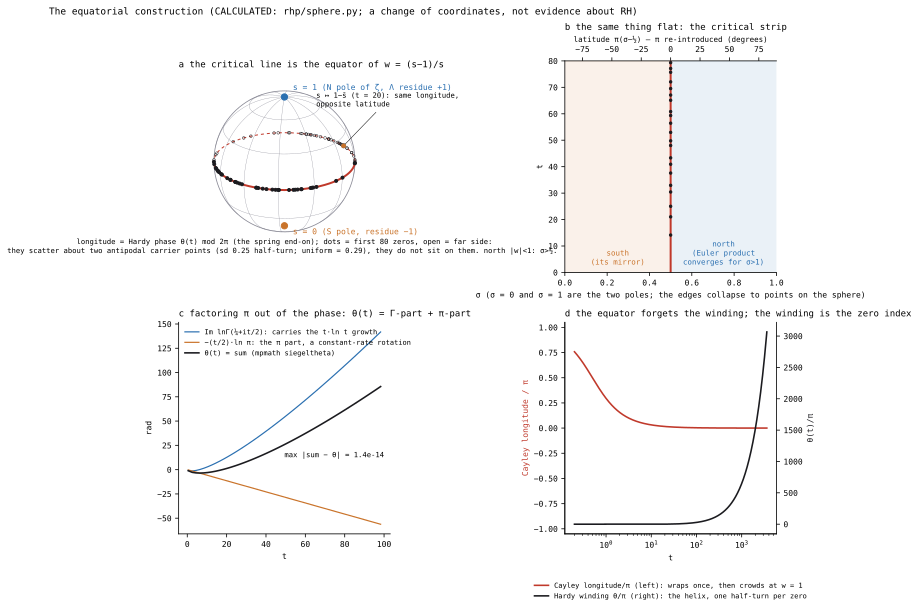

In [3]:
display(SVG(filename=str(equator.build())))

Reading the figure.
* **a** is the sphere. Longitude is the Hardy phase, so the end-on spring is a circle; the zeros scatter about its two antipodal carrier points (θ ≡ π/2 mod π).
  **Measured:** frac(θ(γ)/π) has mean 0.50 and sd 0.25 (uniform would be 0.29). That is a weak bunching. An earlier draft of the code comment said the zeros
  "land on two spots"; that was wrong and is corrected (§7, item 1). The carrier statement of notebook 03 is about *index* matching, not about a mod-π phase.
* **b** is the same object flat. Latitude π(σ − ½) is the chart that literally re-introduces π; the Cayley latitude is the conformal one. They agree on the equator.
* **c** factors π out of the phase: θ(t) = Im ln Γ(¼ + it/2) − (t/2)·ln π. The π part is a *constant-rate rotation*; all of the t·ln t growth is in Γ.
  On the line, |π^{s/2}| = π^{1/4} is constant: factoring π out of ζ = π^{s/2}·Λ/Γ(s/2) leaves a pure phase on the equator. (Whether this is the author's "leaves the ½" is for the author to say.)
* **d** is what the flat circle forgets. The Cayley longitude wraps once and crowds at w = 1; the Hardy phase winds N(T) = θ/π + 1 + S times — the zero index.

In [4]:
t = np.array([10.0, 100.0, 1000.0])
g, p, tot = S.theta_split(t)
print("Γ part   :", np.round(g, 4)); print("π part   :", np.round(p, 4)); print("θ        :", np.round(tot, 4), "  sum−θ max", np.max(np.abs(g+p-tot)))
a, b = S.zeta_pi_factored(0.5 + 10j)
print("π^{s/2} =", complex(a), " |.|=", abs(complex(a)), " π^¼ =", math.pi**0.25)
print("π^{s/2}·Λ/Γ(s/2) =", complex(a*b), "   ζ(½+10i) =", uns.zeta_line(10.0))
fr = (uns_theta := __import__('rhp.bigpath', fromlist=['x']).theta_fast(zeros)) / np.pi % 1
print(f"frac(θ(γ)/π): mean {fr.mean():.3f}  sd {fr.std():.3f}  (uniform: 0.500, 0.289)")

Γ part   : [   2.6566  145.2087 2606.9114]
π part   : [  -5.7236  -57.2365 -572.3649]
θ        : [  -3.0671   87.9722 2034.5464]   sum−θ max 4.440892098500626e-16
π^{s/2} = (1.128308791030833-0.7066633731756983j)  |.|= 1.3313353638003897  π^¼ = 1.3313353638003897
π^{s/2}·Λ/Γ(s/2) = (1.5448952202967527-0.11533646527127338j)    ζ(½+10i) = (1.5448952202967527-0.11533646527127338j)
frac(θ(γ)/π): mean 0.496  sd 0.254  (uniform: 0.500, 0.289)


## 2. Two counter-rotating waves per term, and where they stand still  (ESTABLISHED structure; CALCULATED)

Each term n of the approximate functional equation is a pair: forward n^{−s} and mirror χ(s)·n^{−(1−s)}. Their moduli are n^{−σ} and |χ|·n^{σ−1}; the ratio is
r = |χ|·n^{2σ−1} ≈ ((t/2π)/n²)^{½−σ}. On the equator r = 1 for every n: equal counter-rotating phasors = a *linear* polarisation = a pure standing wave.
Off the equator the sum traces an **ellipse** of axial ratio |1−r|/(1+r); it is again a line only where n ≈ √(t/2π), the Riemann–Siegel cut-off. The standing-wave set is a **cross**.

n =  1: r at σ=½, t=250: 1.000000000000
n =  2: r at σ=½, t=250: 1.000000000000
n =  7: r at σ=½, t=250: 1.000000000000
n = 30: r at σ=½, t=250: 1.000000000000
cut-off √(t/2π) = 3.989
  n = 1: r at σ=0.3 = 1.7393   b/a = 0.270
  n = 2: r at σ=0.3 = 1.3181   b/a = 0.137
  n = 3: r at σ=0.3 = 1.1208   b/a = 0.057
  n = 4: r at σ=0.3 = 0.9989   b/a = 0.001
  n = 5: r at σ=0.3 = 0.9136   b/a = 0.045
  n = 8: r at σ=0.3 = 0.7571   b/a = 0.138


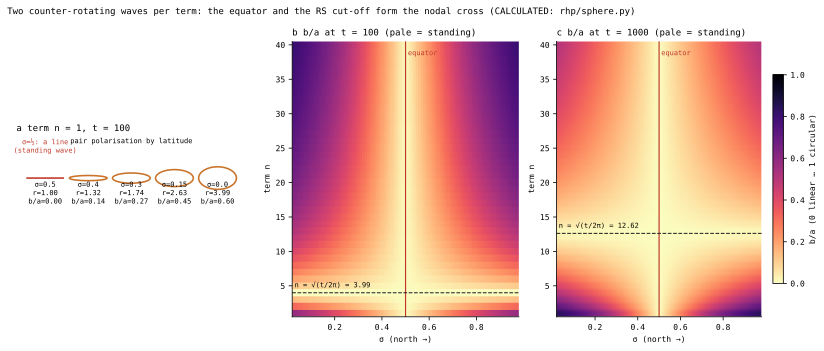

In [5]:
for n in (1, 2, 7, 30):
    print(f"n = {n:2d}: r at σ=½, t=250: {S.amplitude_ratio(n, .5, 250.0):.12f}")
t = 100.0; N = math.sqrt(t/(2*math.pi))
print(f"cut-off √(t/2π) = {N:.3f}")
for n in (1, 2, 3, 4, 5, 8):
    print(f"  n = {n}: r at σ=0.3 = {S.amplitude_ratio(n, .3, t):.4f}   b/a = {S.polarisation(S.amplitude_ratio(n, .3, t)):.3f}")
display(SVG(filename=str(polarisation.build())))

**OURS, in the language of the code.** `forced_sigma` in ValaQuenta is the one-step Newton solve of E(1−2s) = 0 for F = e^{−sE}, B = e^{−(1−s)E} — the single-term version of the above with E = ln n.
Putting the χ factor back (the π-containing factor) turns the balance into h(σ) = (1 − 2σ)·(ln n − ln √(t/2π)): the zero set of h is the cross, and E is measured from the cut-off.
The August valuation already found that σ = ½ here is a property of the *symmetrisation*, true for any f. This section reproduces that and adds the second arm of the cross;
neither arm, by itself, says anything about where the zeros of ζ are.

## 3. The primes on the springs — two different springs  (ESTABLISHED sieve; OURS reading; CALCULATED)

**The sieve spring.** Wrap the integers on a circle of circumference m. n is a multiple of m exactly when it lands on the 0 spot. Every prime p is the 0 spot of its own circle.
**Wheel spring.** The prime p is the rotation e^{−it ln p} of radius p^{−σ}; the wheels turn at ln p and the sum of K of them is Σ p^{−s}.

twin pairs ≤ 10⁷ with p>3: 58979;  centre ≡ 0 (mod 6): 58979   (a theorem: p ≡ 5 mod 6)
5#=30: allowed twin centres 3  = Π(p−2) = 3   fraction 0.1000
7#=210: allowed twin centres 15  = Π(p−2) = 15   fraction 0.0714
11#=2310: allowed twin centres 135  = Π(p−2) = 135   fraction 0.0584
13#=30030: allowed twin centres 1485  = Π(p−2) = 1485   fraction 0.0495

wheels 101,103: antiphase at height t =     160.2;  lag at the first zero t=14.13: 0.2772 rad
wheels 1019,1021: antiphase at height t =    1602.2;  lag at the first zero t=14.13: 0.0277 rad
wheels 10007,10009: antiphase at height t =   15720.5;  lag at the first zero t=14.13: 0.0028 rad
wheels 101,107: antiphase at height t =      54.4;  lag at the first zero t=14.13: 0.8157 rad

e^γ₁ = 1,376,047 — every prime below this sits, as a spike t = ln n, under the first zero


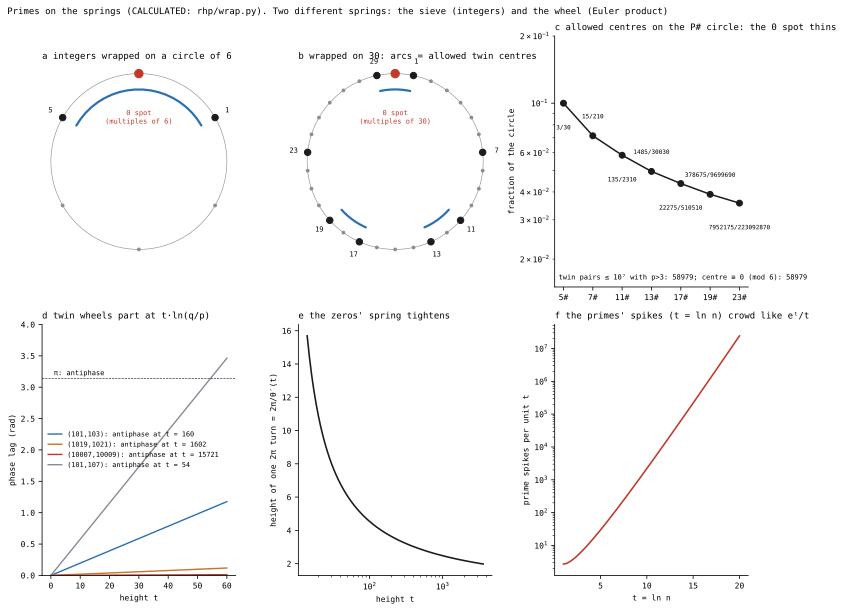

In [6]:
n, ok = W.straddle_check(10**7)
print(f"twin pairs ≤ 10⁷ with p>3: {n};  centre ≡ 0 (mod 6): {ok}   (a theorem: p ≡ 5 mod 6)")
for P in (5, 7, 11, 13):
    m, ok_c = W.allowed_centres(P)
    print(f"{P}#={m}: allowed twin centres {len(ok_c)}  = Π(p−2) = {W.allowed_centre_count(P)}   fraction {len(ok_c)/m:.4f}")
print()
for p, q in ((101, 103), (1019, 1021), (10007, 10009), (101, 107)):
    print(f"wheels {p},{q}: antiphase at height t = {W.antiphase_height(p, q):9.1f};  lag at the first zero t=14.13: {W.wheel_phase_lag(p, q, 14.1347):.4f} rad")
print()
print("e^γ₁ =", f"{math.exp(14.134725141734693):,.0f}", "— every prime below this sits, as a spike t = ln n, under the first zero")
display(SVG(filename=str(awrap.build())))

What this does and does not show.
* Every twin pair above 3 **straddles** the 0 spot of the 6-circle: its centre is the 0 spot. The twins are the **neighbours** of the 0 spot, not the 0 spot. On the 30-circle the allowed centres are
  {0, 12, 18}; on the P#-circle there are Π(p−2) of them, a fraction that thins like Π(1−2/p). This is the singular-series wheel; it is ESTABLISHED arithmetic drawn as a spring. It does not decide the twin prime conjecture.
* On the wheel spring a twin pair is one circle with a slow beat: the phase lag is t·ln(1+2/p) ≈ 2t/p. For (10007, 10009) the wheels do not reach antiphase until t ≈ 15,700, far above anything computed.
  *The gap is carried by the beat and the value by the radius.* This is the precise form of "the index carries more than the value" that the code supports.
* The tension: the Hardy spring's turn height 2π/θ′(t) falls from 15.7 (t = 14) to 2.0 (t = 3600), logarithmically. The prime spikes of the explicit formula (t = ln n) crowd like eᵗ/t. Zeros tighten; primes crowd.

## 4. How far the primes' grip reaches  (CALCULATED; an expected behaviour, quantified)

For K wheels P_K and the truncated Euler product, the branch-free error | ln|ζ| − ln|P_K| | (median over t ∈ [10, 60]) is computed at each latitude. Far north the product converges and more wheels always help.
At the equator the error is smallest near K ≈ 100 and then *grows*: more primes make the picture worse. The first zero appears out of the wheels only as a blurred dip.

K             [3, 10, 30, 100, 300, 1000, 3000, 10000]


sigma= 0.5 [0.301 0.219 0.198 0.089 0.173 0.223 0.321 0.538]  best K = 100


sigma= 0.6 [0.226 0.153 0.119 0.05  0.084 0.08  0.114 0.169]  best K = 100


sigma=0.75 [0.162 0.094 0.054 0.021 0.025 0.019 0.025 0.03 ]  best K = 1000


sigma= 1.0 [0.1   0.032 0.013 0.004 0.004 0.002 0.002 0.002]  best K = 10000


sigma= 1.5 [0.041 0.005 0.001 0.    0.    0.    0.    0.   ]  best K = 10000


K* by latitude: {0.5: 100, 0.55: 100, 0.6: 100, 0.7: 100, 0.8: 1000, 0.9: 1000, 1.0: 10000, 1.25: 10000, 1.5: 10000}


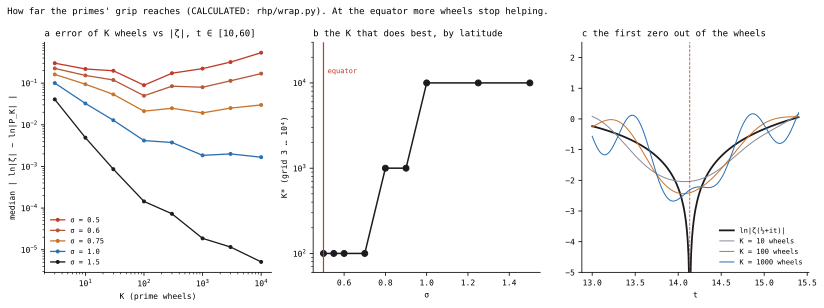

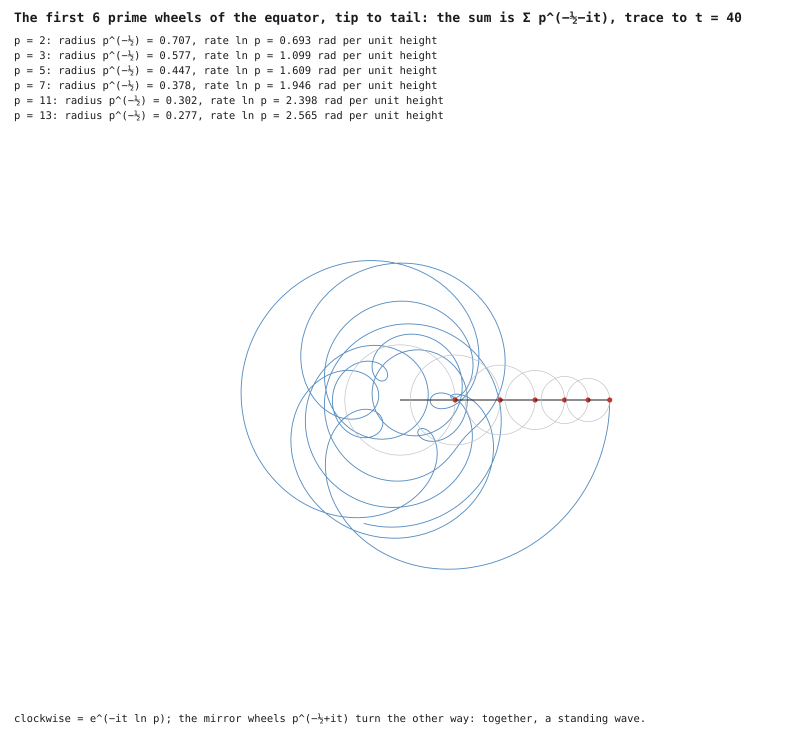

In [7]:
t = np.linspace(10, 60, 101)
Ks = [3, 10, 30, 100, 300, 1000, 3000, 10000]
print("K            ", Ks)
for sg in (0.5, 0.6, 0.75, 1.0, 1.5):
    g = W.euler_grip(sg, t, Ks)
    print(f"sigma={sg:4}", np.round(g, 3), " best K =", Ks[int(np.argmin(g))])
res, kstar = wheels.static()
print("K* by latitude:", kstar)
display(SVG(filename=str(res)))
display(SVG(filename=str(wheels.animated())))

The animated figure (`rhp/atlas_riemann_fermat/wheels_animated.svg`, SMIL; open it in a browser) is the first six prime wheels tip to tail with their sum traced. Equal-and-opposite partner wheels (the mirror) turn the other way:
together a standing wave. **OPEN:** whether a pathway traced through a *significant* number of primes (not 6, not 10⁴) shows a structure beyond what §4 shows; at the equator §4 says the wheel sum stops converging
long before that, so the picture has to be built from the zeros' side (explicit formula, notebook 03), not by adding more wheels.

## 8. The two springs and how they meet  (ESTABLISHED structure; OURS reading; CALCULATED)

**What the author's own pages call them.** `Ainulindale/wiki/47_the_two_trees.md` (measured 2026-08-30): *Telperion — the sieve*: each composite dies on the pass of its smallest prime factor, generation π(spf).
*Laurelin — the un-sieve*: from the ground state "Just Prime Numbers", primes are turned on one at a time and a composite is born when its last needed prime is on, generation π(gpf). Run the extinction from the
largest prime downward and you get Laurelin's book exactly.

**The identification with the two springs here (exact, not analogy).** (i) *Sieve spring:* n lands on the 0 spot of the circle of circumference p first at p = spf(n). (ii) *Wheel spring:* the truncated Euler product P_K is exactly the Dirichlet
series over the p_K-smooth numbers, so n enters the sum when the wheel gpf(n) is switched on. Both springs are made of primes; they differ in the *order* the primes act (smallest-first extinction against largest-last completion).
Primes are not "one spring": a prime is the one number that closes both books at once (spf = gpf).

**Where the clock meets the wheels.** The flat pathway is e^{−iθ(t)}·Z(t). The angle −θ has no primes in it (only Γ and π: §1c). The primes enter through Z(t) = 2Σ_{n≤N} n^{−½}cos(θ(t) − t ln n) + R, each wheel measured *against the clock*.
The wheel n is at rest relative to the clock when θ′(t) = ln n, i.e. n = √(t/2π), t = 2πn²: the horizontal arm of the §2 cross. At height t the clock visits one wheel after another, in order (25.1, 56.5, 100.5, 157.1, … for n = 2, 3, 4, 5).

In [8]:
for n in (2, 3, 4, 5, 7):
    t0 = W.resonance_height(n)
    print(f"n={n}: rest at t = 2π n² = {t0:8.2f};  θ′(t₀) = {uns.theta_prime(t0):.6f},  ln n = {math.log(n):.6f}")
spf, gpf = W.spf_gpf(10**5)
print("n=360 = 2³·3²·5 : Telperion generation π(spf) = 1 (dies on the first pass), Laurelin generation π(gpf) = 3 (born when 5 is on)")
print("fraction of composites ≤ 10⁵ that Telperion kills on the first pass:", round(float(np.mean(spf[4:][~W.sieve(10**5)[4:]] == 2)), 3))

n=2: rest at t = 2π n² =    25.13;  θ′(t₀) = 0.693114,  ln n = 0.693147
n=3: rest at t = 2π n² =    56.55;  θ′(t₀) = 1.098606,  ln n = 1.098612
n=4: rest at t = 2π n² =   100.53;  θ′(t₀) = 1.386292,  ln n = 1.386294
n=5: rest at t = 2π n² =   157.08;  θ′(t₀) = 1.609437,  ln n = 1.609438
n=7: rest at t = 2π n² =   307.88;  θ′(t₀) = 1.945910,  ln n = 1.945910
n=360 = 2³·3²·5 : Telperion generation π(spf) = 1 (dies on the first pass), Laurelin generation π(gpf) = 3 (born when 5 is on)
fraction of composites ≤ 10⁵ that Telperion kills on the first pass: 0.553


**The twin circles.** On the p-circle a pair (n, n+2) must avoid the residues 0 and −2: (p−2)/p of the circle, against ((p−1)/p)² if the two were independent. The product of the ratios over the circles is
Π p(p−2)/(p−1)² → C₂ = 0.66016, the Hardy–Littlewood constant. So the circles' 0 spots are *not* independent, by exactly the twin constant; this is arithmetic, drawn as circles.

circles up to      5: Π p(p−2)/(p−1)² = 0.703125   (C₂ = 0.660162)
circles up to     11: Π p(p−2)/(p−1)² = 0.676758   (C₂ = 0.660162)
circles up to    101: Π p(p−2)/(p−1)² = 0.661311   (C₂ = 0.660162)
circles up to   1009: Π p(p−2)/(p−1)² = 0.660245   (C₂ = 0.660162)
circles up to 100003: Π p(p−2)/(p−1)² = 0.660162   (C₂ = 0.660162)


twin pairs ≤ 10⁷ counted: 58980   Hardy–Littlewood prediction: 58755


gaps between consecutive twin pairs / local mean: mean 0.996  CV 0.912  lag-1 autocorrelation -0.021   (exponential: 1, 1, 0)


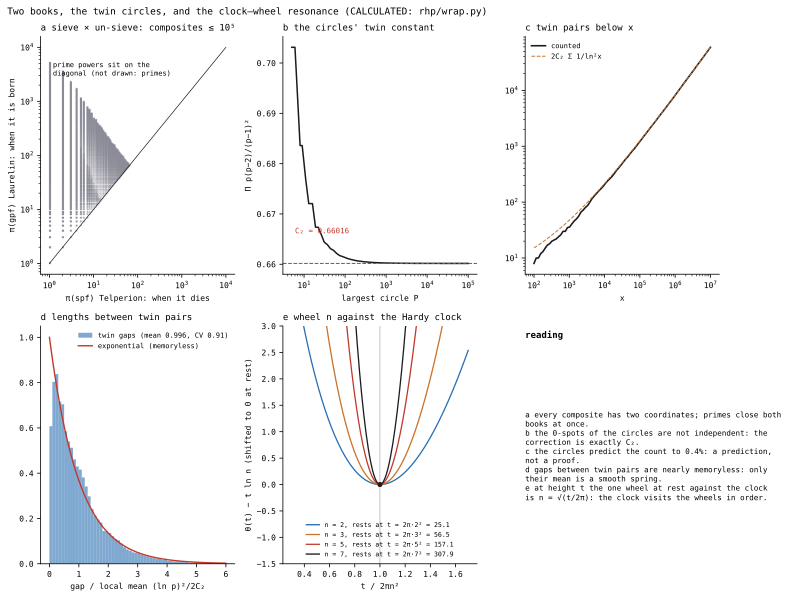

In [9]:
for P in (5, 11, 101, 1009, 100003):
    print(f"circles up to {P:6d}: Π p(p−2)/(p−1)² = {W.singular_series_from_circles(P):.6f}   (C₂ = {W.TWIN_C2:.6f})")
print("twin pairs ≤ 10⁷ counted:", len(W.twin_pairs(10**7)), "  Hardy–Littlewood prediction:", round(W.hl_twin_count(10**7)))
z = W.twin_gaps_normalised(10**7)
print(f"gaps between consecutive twin pairs / local mean: mean {z.mean():.3f}  CV {z.std()/z.mean():.3f}  lag-1 autocorrelation {np.corrcoef(z[:-1], z[1:])[0,1]:+.3f}   (exponential: 1, 1, 0)")
from rhp.atlas_riemann_fermat import twins
display(SVG(filename=str(twins.build())))

What this does and does not show.
* **Not a proof of the twin prime conjecture.** The circles give the *admissibility* of {0, 2} (no circle kills both members of every pair) and the Hardy–Littlewood *prediction* (58,755 against 58,980 counted below 10⁷, 0.4% low).
  Admissibility is necessary, not sufficient; that infinitely many survive is the whole open problem (the parity barrier is why sieve methods stop at bounded gaps, 246 unconditionally, and not at 2).
  The pre-registered P4 in `FourthAgePapers/NoetherWiles/01_predictions.ipynb` says the same of itself: "Admissibility (certain) + infinity (conjectured)".
* **The lengths between twin pairs are not driving anything coherent.** Normalised by their smooth mean (ln p)²/(2C₂) they are close to memoryless (CV 0.91, lag-1 autocorrelation −0.02). If the twin circles shape the pathway it can only be through that smooth mean.
* **The doublet.** The twin wheels p, p+2 are a nearly single rotor with the slow beat t·ln(1+2/p) (§3); in the zeros' picture the pair is a doublet of spikes 2/p apart in t = ln n. Whether pairs of zeros control the pair statistics of the primes is the Montgomery–Goldston pair-correlation relation (ESTABLISHED under RH), not computed here.

## 5. What the code supports of the picture, and what it does not

| Claim | Status |
|---|---|
| The critical line is a great circle; the functional equation is the north–south mirror; the poles are ζ's s = 1 and Λ's s = 0 | ESTABLISHED, `:CALCULATED` §1 |
| π factored out of the phase leaves a constant-rate rotation; the Γ part carries the growth | ESTABLISHED identity, `:CALCULATED` §1c |
| The flat circle forgets the Hardy winding = the zero index | OURS reading of ESTABLISHED θ(t) |
| Each term is a pair of counter-rotating waves; equal on the equator (linear polarisation); the standing-wave set is a cross | ESTABLISHED structure, `:CALCULATED` §2 |
| Twin primes straddle the 0 spot of the 6-circle; the allowed-centre fraction thins like Π(1−2/p) | ESTABLISHED arithmetic, `:CALCULATED` §3 |
| Twin wheels part at t·ln(1+2/p): the gap is the beat | OURS reading, `:CALCULATED` §3 |
| The two springs are Telperion (sieve, by smallest prime factor) and Laurelin (un-sieve, by greatest); the clock visits the wheels at t = 2πn² | OURS reading of the author's measured pages + ESTABLISHED stationary phase, `:CALCULATED` §8 |
| Twin circles give C₂ and the HL count; the lengths between twin pairs are nearly memoryless | ESTABLISHED arithmetic / HEURISTIC prediction, `:CALCULATED` §8 |
| "Primes are on the equator" | **CONJECTURE (reading).** The code shows primes as the *rotation rates* on the equator and as the dual-axis echo spikes, not as points of the circle |
| "Something keeps the zeros on the line, from the factoring side" | **OPEN.** §4 shows the primes' grip fading toward the equator; no mechanism is shown |

## 6. Against 0_RB (what it says here, compared with what the code shows)

Three canonical blocks were read (`ZERO_POLE_CONJUGACY`, `FORCED_SIGMA`, `SIGMA_VALUATION_RHP`). The sedenion / oblique-gear blocks were not compared here.
* **`FORCED_SIGMA`** is the one-term balance E(1−2s) = 0. §2 is that, with the χ factor (the π part) restored: E becomes ln(n/√(t/2π)) and the balance has the second arm n = √(t/2π).
* **`SIGMA_VALUATION_RHP`** records that σ = ½ here is a property of the symmetrisation and the Euler product is "not doing the work at the critical step" (valuation of 2026-08-16). §2 and §4 are consistent with that and give it a picture.
* **`ZERO_POLE_CONJUGACY`** (zeros of L = poles of L⁻¹, s ↦ 1/s, kernel ↔ ∞, s = 1 the unique positive fixed point) has the same shape as w ↦ 1/w with poles at w = 0, ∞ and fixed point w = 1 (the point where the whole critical line closes, t = ±∞).
  The variables are different (an operator ratio against the Cayley coordinate); **no identification is claimed**.

## 7. Anomaly log (Chase Every Anomaly)

1. **Zeros "land on two antipodal spots" (my claim in the first draft of `longitude_hardy`).** Measured: frac(θ/π) mean 0.50, sd 0.25 over all 3066 zeros (first 80: 0.213; 500–3066: 0.256), against 0.289 for a uniform scatter.
   *Verdict:* **CODE/CLAIM error, corrected.** The scatter is S(γ), whose spread is as known (sd ≈ √(ln ln T)/π before wrapping). Nothing anomalous; the carrier is an *index* statement.
2. **More wheels make |ζ| worse at the equator** (median error 0.089 at K = 100, 0.54 at K = 10⁴, t ∈ [10, 60]). *Verdict:* **expected (METHOD)**, the Euler product does not converge absolutely at σ = ½ and its partial sums
   random-walk (Selberg); it is the quantified form of "the primes' grip fades to stillness at the equator". HEURISTIC reading: that is where the zeros' side must take over.
3. **Cayley chart crowds all zeros at one point (w = 1).** First draft of panel a showed 60 zeros in one dot. *Verdict:* **METHOD** (a chart artefact: the flat-projection syndrome in miniature); fixed by using the Hardy phase as longitude and keeping Cayley for latitude and poles.
4. **mpmath precision inherited from other modules** made the functional-equation check fail only when the whole suite ran (not alone). *Verdict:* **CODE**, fixed with `mp.workdps(30)` inside `Λ`, `|χ|` and the mirror check.